# 04 · LLM × léxico: quem identifica melhor os trabalhos de IA?

O notebook 03 marcou os trabalhos de IA por um léxico de termos. É rápido e transparente, mas só
olha palavras. Aqui, uma amostra de 300 resumos (20 por ano) foi classificada pelo Gemini
(`src/classificar_llm.py`), que lê o resumo inteiro e diz se o trabalho usa IA e de que forma.

Perguntas:

1. O LLM e o léxico concordam?
2. Quando discordam, quem está certo? (verificado por leitura humana)
3. A conclusão sobre a ascensão da IA muda conforme o método?

No fim, os tópicos do BERTopic ganham nomes legíveis, gerados pelo LLM
(`src/nomear_topicos.py`).

In [32]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score

PROCESSADOS = Path("../data/processed")
FIGURAS = Path("../reports/figures")
RELATORIOS = Path("../reports")
AUDITORIA = RELATORIOS / "auditoria_llm_lexico.csv"

TINTA = "#52514e"
AZUL, LARANJA, VERMELHO = "#2a78d6", "#eb6834", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA, "xtick.color": TINTA,
    "ytick.color": TINTA, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e8e7e3", "font.size": 10,
})

with open(PROCESSADOS / "classificacao_llm.jsonl", encoding="utf-8") as arquivo:
    llm = pd.DataFrame([json.loads(linha) for linha in arquivo]).drop_duplicates("id", keep="last")

lexico = pd.read_csv(PROCESSADOS / "ia_lexico.csv.gz")
textos = pd.read_csv(PROCESSADOS / "resumos_preprocessados.csv.gz", usecols=["titulo", "resumo"])

amostra = llm.merge(lexico[["id", "ano", "ia"]], on="id").rename(
    columns={"ia": "lexico", "usa_ia": "llm"})
amostra["titulo"] = textos.loc[amostra["id"], "titulo"].to_numpy()
amostra["resumo"] = textos.loc[amostra["id"], "resumo"].to_numpy()
print(f"{len(amostra)} resumos classificados pelo LLM")

300 resumos classificados pelo LLM


## Como o LLM classificou

In [33]:
papeis = {"metodo_principal": "IA é o método principal", "ferramenta_de_apoio": "IA como ferramenta",
          "apenas_mencao": "IA só mencionada", "nao_usa": "Não usa IA"}
amostra["papel_ia"].map(papeis).value_counts().to_frame("resumos")

,resumos
papel_ia,
Não usa IA,157
IA é o método principal,105
IA como ferramenta,33
IA só mencionada,5


## 1. Concordância

A tabela cruza as duas marcações. **Concordância** é a fração de resumos em que os dois métodos
dão a mesma resposta. O **kappa de Cohen** desconta a concordância que aconteceria por acaso:
acima de 0,6 é considerado forte, e acima de 0,8, quase perfeito.

In [34]:
cruzamento = pd.crosstab(amostra["lexico"].map({True: "léxico: IA", False: "léxico: não IA"}),
                         amostra["llm"].map({True: "LLM: IA", False: "LLM: não IA"}))
concordancia = (amostra["lexico"] == amostra["llm"]).mean()
kappa = cohen_kappa_score(amostra["lexico"], amostra["llm"])
print(f"Concordância: {concordancia:.0%} | kappa de Cohen: {kappa:.2f}")
cruzamento

Concordância: 72% | kappa de Cohen: 0.41


llm,LLM: IA,LLM: não IA
lexico,,
léxico: IA,57,4
léxico: não IA,81,158


In [35]:
# Onde o léxico marca IA mas o LLM não, o que o LLM disse sobre o papel da IA?
so_lexico = amostra[amostra["lexico"] & ~amostra["llm"]]
so_lexico["papel_ia"].map(papeis).value_counts().to_frame("resumos")

,resumos
papel_ia,
IA só mencionada,3
Não usa IA,1


In [36]:
# Onde o LLM marca IA mas o léxico não, que papel e que família de IA o LLM apontou?
so_llm = amostra[amostra["llm"] & ~amostra["lexico"]]
pd.crosstab(so_llm["papel_ia"].map(papeis), so_llm["familia"], margins=True)

familia,aprendizado_maquina,aprendizado_profundo,ia_simbolica,All
papel_ia,,,,
IA como ferramenta,9,0,10,19
IA é o método principal,21,3,38,62
All,30,3,48,81


In [37]:
# Comparação justa: o léxico mede IA de aprendizado, então a IA simbólica sai da conta do LLM
amostra["llm_aprendizado"] = amostra["llm"] & (amostra["familia"] != "ia_simbolica")
concordancia_ap = (amostra["lexico"] == amostra["llm_aprendizado"]).mean()
kappa_ap = cohen_kappa_score(amostra["lexico"], amostra["llm_aprendizado"])
print(f"Sem IA simbólica: concordância {concordancia_ap:.0%} | kappa {kappa_ap:.2f}")
pd.crosstab(amostra["lexico"], amostra["llm_aprendizado"])

Sem IA simbólica: concordância 87% | kappa 0.67


llm_aprendizado,False,True
lexico,,
False,206,33
True,5,56


## 2. Quem está certo nas discordâncias?

Concordância não diz qual método acerta. Para isso, os resumos em que os dois discordam vão para
`reports/auditoria_llm_lexico.csv`, com o título, o começo do resumo e a justificativa do LLM.
A coluna `rotulo_humano` deve ser preenchida à mão com **sim** (o trabalho usa IA) ou **não**,
depois de ler cada resumo. Ao rodar o notebook de novo, a avaliação abaixo é calculada.

O arquivo só é criado uma vez, para a rotulagem manual não ser apagada.

In [38]:
discordancias = amostra[amostra["lexico"] != amostra["llm"]].copy()

if not AUDITORIA.exists():
    planilha = discordancias[["id", "ano", "titulo", "lexico", "llm", "papel_ia", "justificativa"]].copy()
    planilha["inicio_resumo"] = discordancias["resumo"].str[:700]
    planilha["rotulo_humano"] = ""
    planilha.to_csv(AUDITORIA, index=False)
    print(f"Criado {AUDITORIA} com {len(planilha)} resumos para rotular")
else:
    print(f"{AUDITORIA} já existe; usando os rótulos preenchidos")

auditoria = pd.read_csv(AUDITORIA, dtype={"rotulo_humano": str})
rotulados = auditoria[auditoria["rotulo_humano"].fillna("").str.strip().str.lower().isin(["sim", "não", "nao"])].copy()
print(f"{len(rotulados)} de {len(auditoria)} discordâncias já rotuladas")

../reports/auditoria_llm_lexico.csv já existe; usando os rótulos preenchidos
85 de 85 discordâncias já rotuladas


In [39]:
if rotulados.empty:
    print("Preencha a coluna rotulo_humano do arquivo de auditoria e rode o notebook de novo.")
else:
    rotulados = rotulados.merge(amostra[["id", "llm_aprendizado"]], on="id")
    rotulados["humano"] = rotulados["rotulo_humano"].str.strip().str.lower().eq("sim")
    acertos = pd.Series({
        "léxico": (rotulados["lexico"] == rotulados["humano"]).mean(),
        "LLM, definição ampla": (rotulados["llm"] == rotulados["humano"]).mean(),
        "LLM, sem IA simbólica": (rotulados["llm_aprendizado"] == rotulados["humano"]).mean(),
    })
    display(acertos.to_frame("acerto nas discordâncias").style.format("{:.0%}"))

,acerto nas discordâncias
léxico,67%
"LLM, definição ampla",33%
"LLM, sem IA simbólica",82%


Nos resumos em que os dois concordam, os dois têm a mesma chance de estar certos ou errados.
Por isso, a comparação acima, feita só nas discordâncias, já mostra qual método erra menos no
total.

## 3. A conclusão muda conforme o método?

,lexico,llm_aprendizado,llm
periodo,,,
2010–2014,6.0,19.0,35.0
2015–2019,16.0,25.0,49.0
2020–2024,39.0,45.0,54.0


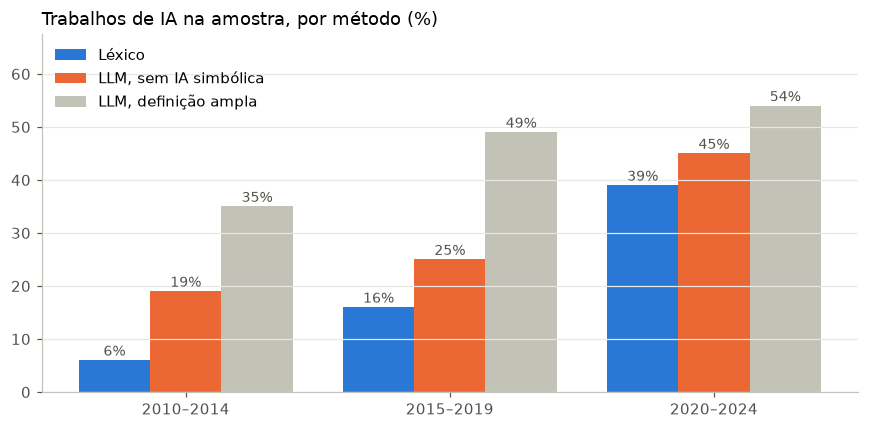

In [40]:
amostra["periodo"] = pd.cut(amostra["ano"], [2009, 2014, 2019, 2024],
                            labels=["2010–2014", "2015–2019", "2020–2024"])
metodos = {
    "lexico": ("Léxico", AZUL),
    "llm_aprendizado": ("LLM, sem IA simbólica", LARANJA),
    "llm": ("LLM, definição ampla", "#c3c2b7"),
}
por_periodo = amostra.groupby("periodo", observed=True)[list(metodos)].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(por_periodo))
largura = 0.27
for i, (coluna, (rotulo, cor)) in enumerate(metodos.items()):
    deslocamento = (i - 1) * largura
    ax.bar(x + deslocamento, por_periodo[coluna], width=largura, color=cor, label=rotulo)
    for j, valor in enumerate(por_periodo[coluna]):
        ax.annotate(f"{valor:.0f}%", (j + deslocamento, valor), xytext=(0, 3),
                    textcoords="offset points", ha="center", color=TINTA, fontsize=9)
ax.set_xticks(x, por_periodo.index)
ax.set_ylim(0, por_periodo.max().max() * 1.25)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Trabalhos de IA na amostra, por método (%)", loc="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "llm_vs_lexico.png", bbox_inches="tight")
por_periodo.round(0)

Com 100 resumos por período, cada porcentagem tem uma margem de erro de cerca de ±9 pontos.
O que importa aqui é a tendência: se os dois métodos mostram o mesmo crescimento, a conclusão do
notebook 03 se sustenta.

## Tópicos com nomes

,tópico,trabalhos,nome,descricao
0,1,1590,Engenharia de Software,"Investiga processos ágeis, evolução de software, gerenciamento de projetos e garantia ..."
1,0,1479,Informática na Educação,"Aborda o desenvolvimento de ferramentas computacionais, ambientes virtuais e metodolog..."
2,2,883,Computação Paralela e Arquitetura,"Analisa o desenvolvimento de sistemas concorrentes, circuitos reconfiguráveis e técnic..."
3,6,860,Bancos de Dados e Big Data,"Desenvolve soluções para modelagem relacional, gerenciamento de dados NoSQL e processa..."
4,5,842,Aprendizado de Máquina,"Concentra-se em algoritmos de classificação, seleção de modelos preditivos, comitês cl..."
5,11,794,Otimização e Algoritmos,"Modela e resolve problemas complexos de programação matemática, métodos exatos, heurís..."
6,3,779,Processamento de Língua Natural,"Foca no processamento e análise automática de textos em língua portuguesa, reconhecime..."
7,4,748,Processamento de Imagens,"Explora técnicas de segmentação, visão computacional, reconstrução tridimensional e re..."
8,13,650,Gestão de Processos de Negócio,"Examina a modelagem conceitual, governança de TI, maturidade organizacional e melhoria..."
9,14,579,Informática em Saúde,Aplica inteligência artificial e análise de dados clínicos para auxílio no diagnóstico...


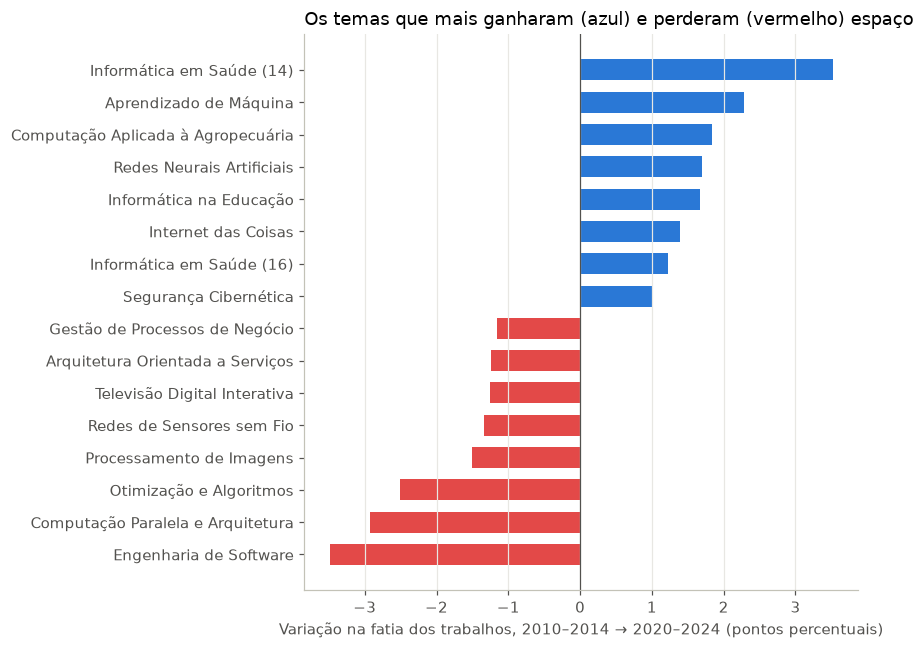

In [41]:
nomes_arquivo = RELATORIOS / "topicos_nomeados.csv"
if nomes_arquivo.exists():
    nomes = pd.read_csv(nomes_arquivo)
    variacao = pd.read_csv(RELATORIOS / "variacao_topicos.csv")
    variacao = variacao.merge(nomes[["tópico", "nome"]], on="tópico", how="left")
    # Dois tópicos podem receber o mesmo nome; o número do tópico desfaz o empate
    repetidos = variacao["nome"].duplicated(keep=False)
    variacao.loc[repetidos, "nome"] += " (" + variacao.loc[repetidos, "tópico"].astype(str) + ")"
    destaque = pd.concat([variacao.head(8), variacao.tail(8)])

    fig, ax = plt.subplots(figsize=(8, 6))
    cores = [VERMELHO if v < 0 else AZUL for v in destaque["variação (p.p.)"]]
    ax.barh(destaque["nome"], destaque["variação (p.p.)"], color=cores, height=0.65)
    ax.axvline(0, color=TINTA, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True, color="#e8e7e3")
    ax.set_xlabel("Variação na fatia dos trabalhos, 2010–2014 → 2020–2024 (pontos percentuais)")
    ax.set_title("Os temas que mais ganharam (azul) e perderam (vermelho) espaço",
                 loc="left", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIGURAS / "variacao_topicos_nomeados.png", bbox_inches="tight")
    pd.set_option("display.max_colwidth", 90)
    display(nomes[["tópico", "trabalhos", "nome", "descricao"]].head(20))
else:
    print("Rode python src/nomear_topicos.py para gerar os nomes dos tópicos.")